In [ ]:
import json
import ufl
import dolfin as dl

#sys.path.append(os.environ.get('HIPPYLIB_PATH', "../../"))
import hippylib as hp
#sys.path.append(os.environ.get('HIPPYFLOW_PATH',"../../"))
import hippyflow as hf

from helpers import *
from generate_samples import *
import math

# Setup Mesh, and Functional spaces and PDE

In [200]:
nx =31; ny = 31
nodes = (nx+1)*(ny+1)
mesh = dl.RectangleMesh(dl.Point(0.0, 0.0), dl.Point(1.0, 1.0), nx, ny)
Vh_STATE = dl.FunctionSpace(mesh, "CG", 2)
Vh_PARAMETER = dl.FunctionSpace(mesh, "CG", 1)
Vh = [Vh_STATE, Vh_PARAMETER, Vh_STATE]

d2v = dl.dof_to_vertex_map(Vh[hp.PARAMETER])
v2d = dl.vertex_to_dof_map(Vh[hp.PARAMETER])


def u_boundary(x, on_boundary):
    return on_boundary and ( x[1] < dl.DOLFIN_EPS or x[1] > 1.0 - dl.DOLFIN_EPS)

u_bdr = dl.Expression("x[1]", degree=1)
u_bdr0 = dl.Constant(0.0)
bc = dl.DirichletBC(Vh[hp.STATE], u_bdr, u_boundary)
bc0 = dl.DirichletBC(Vh[hp.STATE], u_bdr0, u_boundary)

f = dl.Constant(0.0)
#f = dl.Expression("sin(2*pi*x[0]) * exp(x[1]+ x[0])", degree=5)

def pde_varf(u,m,p):
    return ufl.inner(m * ufl.grad(u), ufl.grad(p)) * ufl.dx - f*p*ufl.dx
    

pde = hp.PDEVariationalProblem(Vh, pde_varf, bc, bc0, is_fwd_linear=True)



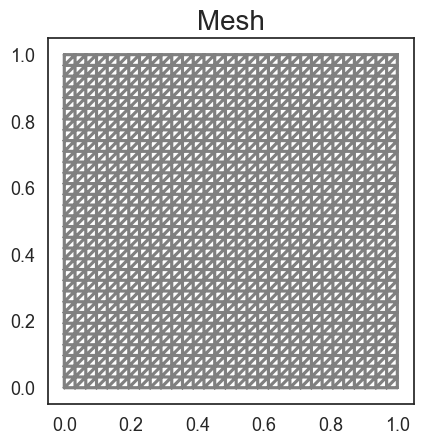

In [201]:
hp.nb.plot(mesh,subplot_loc=121, mytitle="Mesh", show_axis='on')

# Target location
## Location in the domain $\Omega$, where we have our observation

In [202]:
u_trial = dl.TrialFunction(Vh[hp.STATE])
u_test = dl.TestFunction(Vh[hp.STATE])

M_U = dl.assemble(dl.inner(u_trial,u_test)*dl.dx)
I_U = hf.StateSpaceIdentityOperator(M_U)
#observable = hf.LinearStateObservable(pde,M_U)
observable = hf.LinearStateObservable(pde,I_U)
Jm = hf.ObservableJacobian(observable)

m_trial = dl.TrialFunction(Vh[hp.PARAMETER])
m_test =  dl.TestFunction(Vh[hp.PARAMETER])

## Setup the Gempy

In [203]:
if torch.backends.mps.is_available() and torch.backends.mps.is_built():
    #device = torch.device("mps")
    device = torch.device("cpu")
    print("Using MPS device")
elif torch.cuda.is_available():
    device = torch.device("cuda")
    print("Using CUDA device")
else:
    device = torch.device("cpu")
    print("Using CPU device")

Using MPS device


In [204]:

# data = generate_input_output_gempy_data_(mesh=mesh, number_samples=2,device=device,nodes=nodes, slope=180,filename=None)
# c,m_data, dmdc_data = np.array(data["input"]),2 * np.array(data["Gempy_output"]), 2 * np.array(data["Jacobian_Gempy"])
# c.shape, type(c), m_data.shape, type(m_data),dmdc_data.shape, type(dmdc_data)

In [205]:
import h5py

import os
current_folder = os.getcwd()
Sampling_type = current_folder.split("/")[-1]
print("Sampling_type:", Sampling_type)
parent_folder = os.path.dirname(current_folder)
model_name = parent_folder.split("/")[-1]
print("Model name:", model_name)
directory_path = "../../Results/"+str(model_name)+"/"+str(Sampling_type)+"/Nodes_"+str(nodes)
filename = directory_path + "/gempy_data.h5"


with h5py.File(filename, "r") as f_data:
    c = f_data["input"][:]
    m_data = 2 * f_data["Gempy_output"][:]
    dmdc_data = 2 * f_data["Jacobian_Gempy"][:]

#c, m_data, dmdc_data = np.array(data["input"]),2 * np.array(data["Gempy_output"]), 2 *np.array(data["Jacobian_Gempy"])
n=math.ceil(2**13 / 0.6) # Number of samples we need
c=c[:n]
m_data = m_data[:n]
dmdc_data = dmdc_data[:n]
c.shape, type(c), m_data.shape, type(m_data),dmdc_data.shape, type(dmdc_data)

Sampling_type: gaussian
Model name: SD2LSP


((13654, 1),
 numpy.ndarray,
 (13654, 1024),
 numpy.ndarray,
 (13654, 1024, 1),
 numpy.ndarray)

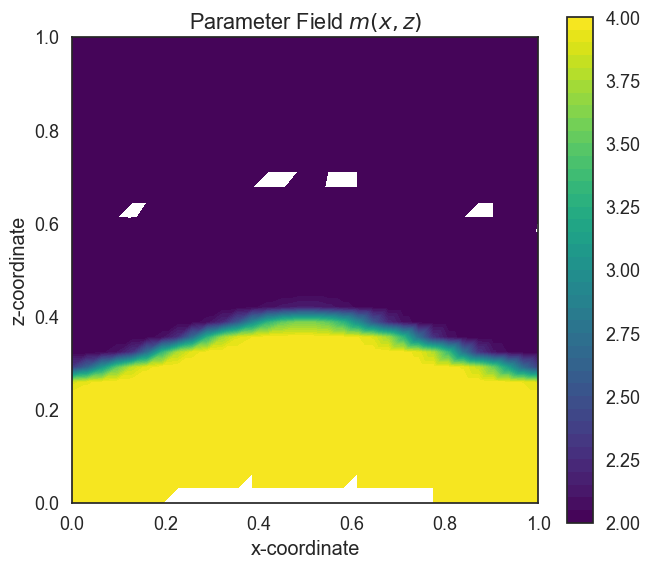

In [206]:
m = dl.Function(Vh[hp.PARAMETER])
m_nodes_hat = dl.Function(Vh[hp.PARAMETER])
m_hat = dl.Function(Vh[hp.PARAMETER])
m.vector().set_local(m_data[0,:][d2v])
A= m.vector().get_local()
#plt.axis("off")
col = dl.plot(m,cmap="viridis" )
fig = plt.gcf()
fig.colorbar(col) 
# Add axis labels and title
plt.xlabel("x-coordinate")
plt.ylabel("z-coordinate")
plt.title("Parameter Field $m(x,z)$")

plt.tight_layout()
fig.set_size_inches(6, 6)
#plt.savefig("debug_output.png", dpi=300)

In [207]:
# import time

# m = dl.Function(Vh[hp.PARAMETER])
# m_nodes_hat = dl.Function(Vh[hp.PARAMETER])
# m_hat = dl.Function(Vh[hp.PARAMETER])
# for i in range(200):
#     plt.clf()
#     m.vector().set_local(m_data[i,:][d2v])
#     A= m.vector().get_local()
#     #plt.axis("off")
#     #col = dl.plot(m,cmap="viridis" )
#     #fig, ax = plt.subplots(figsize=(15, 15))
#     im =plt.imshow(A[v2d].reshape((nx+1,ny+1)),cmap="viridis" ,origin='lower',extent=[0, 1, 0, 1],interpolation='bilinear')
#     fig = plt.gcf()
#     fig.colorbar(im) 
#     # Add axis labels and title
#     plt.xlabel("x-coordinate")
#     plt.ylabel("z-coordinate")
#     plt.title("Parameter Field: $m(\\boldsymbol{x}; k)$")
#     #plt.tight_layout()
#     #fig.set_size_inches(6, 6)
#     plt.savefig("debug_output.png")
#     time.sleep(0.1)  # Pauses for 2 seconds

In [208]:
# plt.imshow(A[v2d].reshape((nx+1,ny+1)),cmap="viridis" ,origin='lower',extent=[0, 1, 0, 1],interpolation='bilinear')
# # Set figure size to 3x3 inches
# plt.gcf().set_size_inches(3, 3)

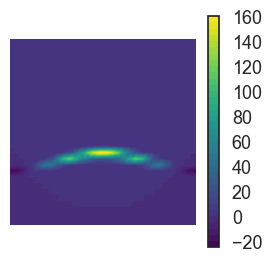

In [209]:
for i in range(c.shape[1]):
    m_nodes_hat.vector().set_local(dmdc_data[2,:,i][d2v])
    plt.axis("off")
    col= dl.plot(m_nodes_hat, cmap="viridis")
    fig = plt.gcf()
    fig.colorbar(col) 
    fig.set_size_inches(3, 3)
    plt.show()

## Generate samples of the state.


NOTE I AM USING A SIMPLE MPI RANK PROCESS SO THE ARRAY OPERATION `.get_local()` MAY NEED TO BE MODIFIED IN AN MPI PARALLEL CONTEXT. HOWEVER FOR PROBLEMS THAT ARE THIS SMALL THERE IS NO JUSTIFICATION FOR MPI PARALLELISM FOR THE MESH

In [210]:
M_M = dl.assemble(dl.inner(m_trial,m_test)*dl.dx)

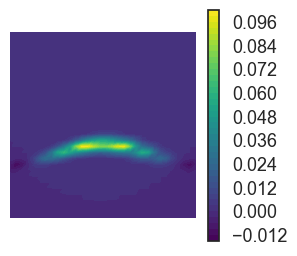

In [211]:
for i in range(c.shape[1]):
    m_nodes_hat.vector().set_local(dmdc_data[0,:,i][d2v])
    M_M.mult(m_nodes_hat.vector(), m_hat.vector())
    plt.axis("off")
    col= dl.plot(m_hat, cmap="viridis")
    #dl.plot(m_nodes_hat)
    fig = plt.gcf()
    fig.colorbar(col) 
    fig.set_size_inches(3, 3)
    plt.show()

In [212]:
nsamples = c.shape[0]

m = dl.Function(Vh[hp.PARAMETER])

u = dl.Function(Vh[hp.STATE])
uadj = dl.Function(Vh[hp.ADJOINT])

dU = u.vector().get_local().shape[0]

dC = c.shape[1]

# once you have modified the means of c->m(c) comment this
uhat = dl.Function(Vh[hp.STATE])
m_nodes_hat = dl.Function(Vh[hp.PARAMETER])
m_hat = dl.Function(Vh[hp.PARAMETER])
u_data = np.zeros((nsamples,dU))
J_data = np.zeros((nsamples, dU, dC))

plotting = False
for sample_index in range(nsamples):
    # Do something here to modify the coefficients
   
    m_values = m_data[sample_index,:]
    m.vector().set_local(m_values[d2v]) #uncomment this
    # m.vector().set_local(m_values[d2v] +0.1*np.random.randn(m_values.shape[0])) #comment this
    if plotting:
        #plt.axis("off")
        dl.plot(m,cmap="viridis")
        fig = plt.gcf()
        fig.set_size_inches(1, 1)
        plt.show()
        # Plot with color

    
    x = [u.vector(),m.vector(),uadj.vector()]
    pde.solveFwd(x[hp.STATE], x)
    
    Jm.observable.setLinearizationPoint(x)
    
    
    # Get the data
    u_data[sample_index,:] = x[hp.STATE].get_local()
    # Calculate the Jacobian
    for component in range(dC):
        m_nodes_hat.vector().set_local(dmdc_data[sample_index,:,component][d2v]) 
        Jm.mult(m_nodes_hat.vector(),uhat.vector()) 
        # Multiply dmdc by Mass matrix.
        # M_M.mult(m_nodes_hat.vector(), m_hat.vector()) 
        # Jm.mult(m_hat.vector(),uhat.vector()) 
        J_data[sample_index,:,component] = uhat.vector().get_local()
    
u_data.shape, J_data.shape

((13654, 3969), (13654, 3969, 1))

In [213]:
# import time
# u_hat = dl.Function(Vh[hp.STATE])
# for i in range(u_data.shape[0]):
#     plt.clf()  # clear the figure before each new plot
#     u_hat.vector().set_local(u_data[i,:])
#     #A= u_hat.vector().get_local()
#     #plt.axis("off")
#     col = dl.plot(u_hat,cmap="viridis" )
#     plt.colorbar(col)  # <-- add the colorbar
    
#     #fig.colorbar(col) 
#     # Add axis labels and title
#     plt.xlabel("x-coordinate")
#     plt.ylabel("z-coordinate")
#     plt.title("State Field $u(x,z)$")
#     #plt.tight_layout()
#     #fig.set_size_inches(6, 6)
#     plt.savefig("debug_output_state.png")
#     time.sleep(0.2)  # Pauses for 2 seconds

In [ ]:

filename_final = directory_path + "/POD_data.h5"

with h5py.File(filename_final, "w") as final_data:
    final_data["Gempy_Inputs"] = c.tolist()
    final_data["PDE_outputs"] = u_data.tolist()
    final_data["Jacobian"] = J_data.tolist()
    


## (Linear) encoders and decoders.

Please consult our papers for a more in-depth discussion. E.g., [section 2.4 in this work](https://arxiv.org/abs/2411.12726)

We can expand a function on an orthonormal basis as

$$ u(x) = \sum_{i=1}^\infty \langle u(x),\phi_i(x)\rangle_\mathcal{U} \phi_i(x)$$

and the truncated representation

$$ u(x) = \sum_{i=1}^r \langle u(x),\phi_i(x)\rangle_\mathcal{U} \phi_i(x)$$

The encoder is the mapping from the data $u(x)$ to its truncated coefficient expansion $\mathcal{E}_r u \in \mathbb{R}^{r}$

$$ \mathcal{E}_r u = \left[\langle u,\phi_i\rangle_\mathcal{U}\right]_{i=1}^r \in \mathbb{R}^{r}$$

The decoder maps this data back to the function space (e.g., the basis expansion operation), given $\alpha \in \mathbb{R}^r$ we have

$$ \mathcal{D}_r \alpha  = \sum_{i=1}^r \alpha_i \phi_i$$

The encoder has the effect of the inner product $\langle \cdot,\cdot\rangle_\mathcal{U}$, e.g., the mass matrix in finite elements, each column of it is $\langle \cdot, \phi\rangle_\mathcal{U}$, so we call it `Mphi` $\in \mathbb{R}^{d_u \times r}$. Likewise we call the decoder `\phi` since its columns are just the basis vectors

### Encoding u data

The mapping to the coefficients of u is $u_r = \mathcal{E}_r u$. In numpy this is `ur_data = Mphi.T@u_data`

### Decoding the u data

We decode with the basis: $\mathcal{D}_r u_r$. In numpy this is `phi@ur_data`

### Encoding and decoding the derivatives.

The derivative of the map is 

$$ Du(c) \in \mathcal{L}(\mathbb{R}^{d_c},\mathcal{U}) $$

that is, the space of linear operators from $\mathbb{R}^{d_c}$ into $\mathcal{U}$. We want to remove the high-dimensionality associated with $\mathcal{U}$

This is done with the encoder operator:

$$\mathcal{E}_r Du(c) \in \mathbb{R}^{r\times d_c}$$

In [223]:
# # Encode the u_data

# ur = np.einsum('ur,du->dr',Mphi_r,u_data)

# # Encoder the Du_data

# # dc = 2
# # Du_data = np.random.randn(nsamples,dU,dc)
# # Dur_data = np.einsum('ur,duc->drc',Mphi,Du_data)

## Training data

The training data then is inputs (`c_data` \in $\mathbb{R}^{nsamples\times dc}$) and outputs (`ur_data`, `Dur_data`)


## To figure out in the $Du(c)$ calculations

The derivative I believe should have the mass matrix for $\mathcal{M}$ space in it:

$$ Du(c) = D_m(u(m(c)) \frac{dm}{dc} = -\left[\frac{\partial R}{\partial u}\right]^{-1}\frac{\partial R}{\partial m} \frac{dm}{dc}$$

In the other notebook we are evaluating the mapping from $c\mapsto m_\text{node}$, the nodal representation of $m$, but not the function. The mapping to the function requires the mass matrix

The torch gempy code will give you
$$ \frac{dm_\text{node}}{dc}$$

and we need in the end
$$ \frac{dm}{dc} = M_\mathcal{M} \frac{dm_\text{node}}{dc}$$

In [224]:
# Calculating the mass matrix for $\mathcal{M}$


In [225]:
# m_trial = dl.TrialFunction(Vh[hp.PARAMETER])
# m_test = dl.TestFunction(Vh[hp.PARAMETER])

# M_M = dl.assemble(dl.inner(m_trial,m_test)*dl.dx)

## Final form of the pre-reduced Jacobian

$$ Du(c) = -\left[\frac{\partial R}{\partial u}\right]^{-1}\frac{\partial R}{\partial m} M_\mathcal{M}\frac{dm_\text{node}}{dc}$$

Where 

$$ \frac{dm_\text{node}}{dc} \in \mathbb{R}^{d_\text{node}\times dc}$$

is the nodal Jacobian you will get as the output from the gempy torch automatic differntiation

## DOF ORDERING FOR m

You will also need to check the correct degree of freedom mapping for $m$

It will likely be something like the code we had: `m_values[d2v]`

So the output of your torch AD for dm_node/dc will need to have each column reordered using the d2v re-ordering.

When in doubt, plot everything. Do you see that I am constantly plotting to make sure that I am dealing with the right thing? If you get the vertex to dof map wrong you will be able to see it immediately via plotting columns of the Jacobian.